# 3. Classification

*Series:* [1. Data processing](01_data_processing.ipynb) · [2. Exploratory analysis](02_exploratory_analysis.ipynb) · **[3. Classification](03_classification.ipynb)** · [4. Clustering](04_clustering.ipynb) · [5. Explainability](05_explainability.ipynb)

---

How well can eight routine measurements predict diabetes, and which model does
it best?

The second half of that question turns out to have an unexpected answer.

Three rules govern everything below.

1. **Nothing is fitted outside a pipeline.** Imputation and scaling are refit on
   every cross-validation fold. Computing a median over the full dataset and
   then splitting inflates every number that follows.
2. **Nothing is selected on the test set.** Hyperparameters and the decision
   threshold both come from out-of-fold predictions on the training half. The
   test set is scored once.
3. **Accuracy is read against a baseline.** That baseline is 65.1%.

In [1]:
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from pima import evaluate, plots
from pima.data import TARGET, load_processed, split
from pima.models import feature_names

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plots.use_style()

df = load_processed()
X_train, X_test, y_train, y_test = split(df)
print(f"train {len(X_train)}  ({y_train.mean():.1%} diabetic)")
print(f"test  {len(X_test)}  ({y_test.mean():.1%} diabetic)")

train 614  (34.9% diabetic)
test  154  (35.1% diabetic)


## Why imputation lives inside the pipeline

This is worth spelling out, because the tempting shortcut is the one that
breaks this dataset in particular.

Filling a missing glucose with the median glucose *of that patient's outcome
group* is a common move. It tells the features what the label is, so the model
then predicts the label from a number derived from the label. It scores well and
has learned nothing. On a dataset that is 48.7% missing in one column, the
inflation is severe.

Median imputation without the target still leaks, more subtly, if the median is
computed before the split, since the training rows then carry information from
the test rows. Keeping imputation as a pipeline step avoids both, and
`test_models.py::test_preprocessor_is_fit_on_training_data_only` enforces it.

## Does the imputation strategy matter?

Notebook 1 found the missing values nested inside one another, which suggests
clever imputation has little to work with. Six configurations, each scored by
repeated 5-fold cross-validation on the training half only.

In [2]:
ablation = evaluate.imputation_ablation(
    X_train, y_train,
    LogisticRegression(max_iter=5000, C=0.1, class_weight="balanced"),
)
ablation

,imputer,missing_indicators,roc_auc,roc_auc_sd,avg_precision
0,iterative,False,0.8354,0.0329,0.7272
1,mean,False,0.8353,0.0333,0.7270
2,median,False,0.8352,0.0336,0.7280
3,iterative,True,0.8317,0.0376,0.7293
4,mean,True,0.8310,0.0372,0.7299
5,median,True,0.8308,0.0373,0.7297


It does not. The spread across every imputer and both indicator settings is
about 0.005 ROC AUC against a cross-validation standard deviation of 0.033,
roughly a sixth of the noise. Iterative imputation, which models each feature
from the others and costs considerably more to run, buys nothing over a median.

This is what notebook 1 predicted from the nested missingness. For the patients
with missing insulin the correlated features are missing too, so the iterative
model has nothing to condition on and falls back to approximately the marginal
median.

Missing-indicator columns are slightly negative for ROC AUC and slightly
positive for average precision, so on balance they do nothing. That was notebook
1's other prediction, and it holds.

This is a useful negative result. The rest of the analysis uses median
imputation with indicators, chosen as the simplest defensible default given
that no configuration outperformed the others.

## The candidates

Five, including a baseline that serves as a reference point. Each is
grid-searched in 5-fold CV on the training half, then the tuned model is
re-scored with repeated (5x5) stratified CV for a stable estimate.

They differ in what they can represent: logistic regression is linear, the RBF
SVM draws curved boundaries, and the two ensembles capture interactions. If the
problem has structure a linear model misses, the flexible models should find
it.

In [3]:
best, leaderboard = evaluate.select_models(X_train, y_train)
leaderboard[["model", "roc_auc", "roc_auc_sd", "average_precision",
             "balanced_accuracy", "accuracy"]]

,model,roc_auc,roc_auc_sd,average_precision,balanced_accuracy,accuracy
0,random_forest,0.8352,0.0338,0.7115,0.7560,0.7668
1,svm_rbf,0.8344,0.0364,0.7324,0.7467,0.7531
2,logistic_regression,0.8308,0.0373,0.7297,0.7426,0.7524
3,gradient_boosting,0.8297,0.0351,0.7204,0.7347,0.7700
4,majority_class,0.5000,0.0000,0.3485,0.5000,0.6515


In [4]:
leaderboard[["model", "best_params"]]

,model,best_params
0,random_forest,"{'class_weight': 'balanced', 'max_depth': 10, ..."
1,svm_rbf,"{'C': 10.0, 'class_weight': 'balanced', 'gamma..."
2,logistic_regression,"{'C': 0.1, 'class_weight': 'balanced'}"
3,gradient_boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, '..."
4,majority_class,{}


## The models score the same

The four genuine models span 0.8297 to 0.8352 ROC AUC, a range of 0.0055,
against a cross-validation standard deviation of about 0.035. The gap between
best and worst is a sixth of the run-to-run noise of any one of them.

There is no winner to declare. A linear model with two hyperparameters matches
a 400-tree forest and a boosted ensemble, so the flexible models found no
non-linear structure worth having. Notebook 2 predicted this from the monotone
prevalence curves and the overlapping distributions: the limit is in the data,
and further model shopping will not move it.

The `majority_class` row scores 65.2% accuracy having learned nothing, and the
tuned models reach 75 to 77%. The useful way to describe that is about eleven
points above always answering no.

## Ranking and calibration

Out-of-fold predictions, where each patient is scored by a model that did not
train on them, give an unbiased view of the curves and are what the threshold is
chosen on.

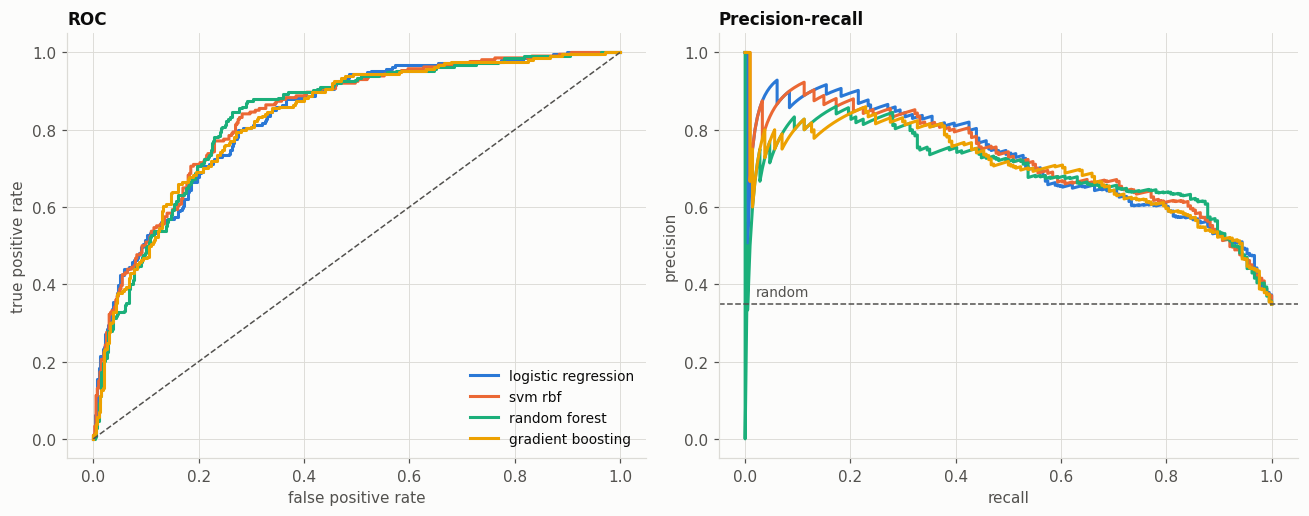

In [5]:
oof = {name: evaluate.out_of_fold_proba(model, X_train, y_train)
       for name, model in best.items() if name != "majority_class"}
curves = {name: (y_train.to_numpy(), proba) for name, proba in oof.items()}
plots.roc_and_pr(curves, base_rate=y_train.mean());

The curves sit on top of one another, as the leaderboard suggested. The
precision-recall panel is the more sobering of the two: to catch 80% of
diabetics, every model accepts a precision near 0.6, meaning two in five
flagged patients do not have diabetes.

,n,mean_predicted,observed
0,123,0.119,0.049
1,123,0.243,0.114
2,122,0.398,0.328
3,123,0.616,0.480
4,123,0.864,0.772


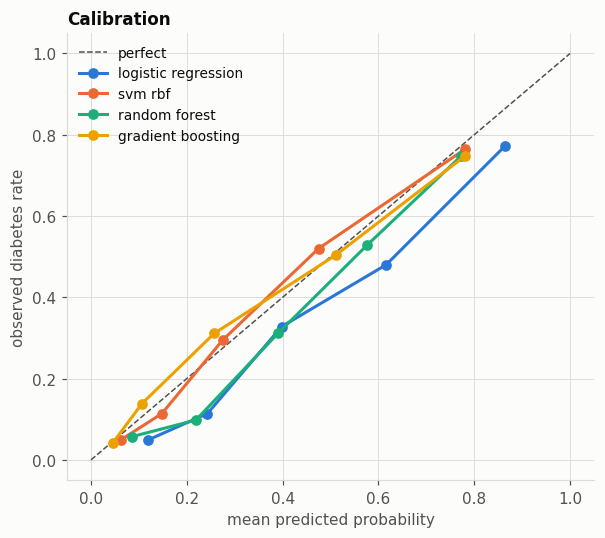

In [6]:
calibration = {name: evaluate.calibration_table(y_train, proba, n_bins=5)
               for name, proba in oof.items()}
plots.calibration(calibration);
calibration["logistic_regression"]

Calibration is imperfect in an instructive way. Most of the tuned models carry
`class_weight="balanced"`, which reweights the minority class to improve recall
and distorts the probabilities in the process. The model says 0.86 for a group
where 77% are diabetic, and 0.12 for a group where 5% are.

These outputs work as a ranking over patients and should not be read as risk
estimates. If a calibrated probability were required, the fix is to drop the
class weighting and recover the operating point using the threshold, which is
the next section.

## Choosing the decision threshold

`predict()` uses 0.5, which is not a neutral choice. It asserts that a missed
diabetic costs the same as a false alarm. In screening the two differ: a false
alarm costs a confirmatory test, while a missed case costs a delayed diagnosis.

Four rules, all evaluated on out-of-fold predictions so the test set stays
sealed.

In [7]:
model_name = leaderboard.loc[0, "model"]
oof_best = oof[model_name]

thresholds = {rule: evaluate.choose_threshold(y_train, oof_best, criterion=rule)
              for rule in ("f1", "youden", "min_recall", "cost")}

pd.DataFrame([{"rule": rule, **evaluate.threshold_metrics(y_train, oof_best, t)}
              for rule, t in thresholds.items()])

,rule,threshold,roc_auc,avg_precision,brier,accuracy,recall,precision,specificity,tp,fp,fn,tn
0,f1,0.4300,0.8359,0.6973,0.1594,0.7752,0.8458,0.6329,0.7375,181,105,33,295
1,youden,0.4300,0.8359,0.6973,0.1594,0.7752,0.8458,0.6329,0.7375,181,105,33,295
2,min_recall,0.4497,0.8359,0.6973,0.1594,0.7736,0.8037,0.6394,0.7575,172,97,42,303
3,cost,0.3897,0.8359,0.6973,0.1594,0.7606,0.8785,0.6084,0.6975,188,121,26,279


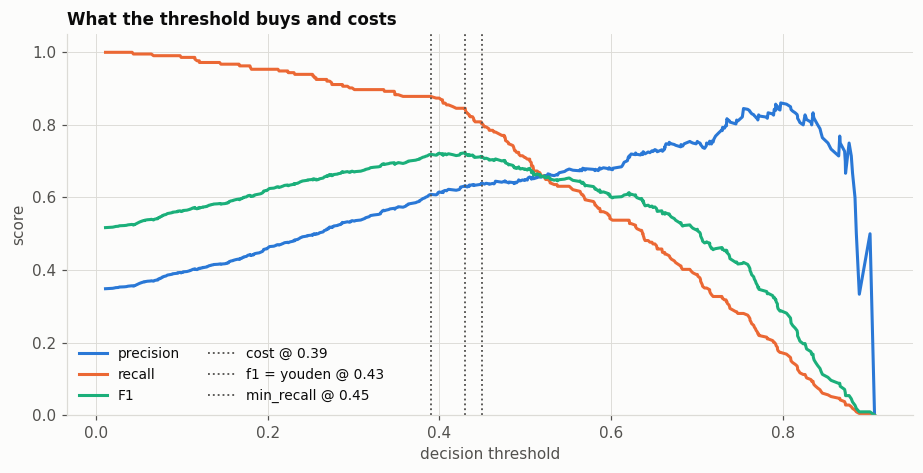

In [8]:
plots.threshold_sweep(y_train.to_numpy(), oof_best, marked=thresholds);

Every rule lands between 0.39 and 0.45, so the library default would have been
the wrong operating point under all four objectives.

The trade-off is explicit in the table. Moving from the cost-weighted threshold
(0.39, pricing a missed case at five false alarms) to the recall-constrained one
(0.45) converts 16 caught diabetics into 16 missed ones in exchange for 24 fewer
false alarms. That is a clinician's judgement to make, and the modeller's job is
to put the numbers in front of them instead of shipping 0.5 unexamined.

## Test set results

Everything above used the training half. Each model now carries a threshold
chosen from its own out-of-fold predictions and is scored once on the 154
held-out patients. Intervals are percentile bootstraps over the test set.

In [9]:
rows = []
for name, fitted in best.items():
    own_threshold = evaluate.choose_threshold(
        y_train, evaluate.out_of_fold_proba(fitted, X_train, y_train), criterion="f1"
    )
    proba = fitted.predict_proba(X_test)[:, 1]
    lo, hi = evaluate.bootstrap_ci(y_test, proba)
    rows.append({"model": name,
                 **evaluate.threshold_metrics(y_test, proba, own_threshold),
                 "roc_auc_95ci": f"[{lo}, {hi}]"})

pd.DataFrame(rows)[["model", "roc_auc", "roc_auc_95ci", "avg_precision", "brier",
                    "accuracy", "recall", "precision", "fn", "fp"]]

,model,roc_auc,roc_auc_95ci,avg_precision,brier,accuracy,recall,precision,fn,fp
0,majority_class,0.5000,"[0.5, 0.5]",0.3506,0.3506,0.6494,0.0000,0.0000,54,0
1,logistic_regression,0.8569,"[0.7955, 0.912]",0.7189,0.1557,0.7403,0.8333,0.5921,9,31
2,svm_rbf,0.8317,"[0.7628, 0.8944]",0.7325,0.1547,0.6883,0.8333,0.5357,9,39
3,random_forest,0.8504,"[0.7868, 0.9092]",0.7603,0.1537,0.7468,0.7778,0.6087,12,27
4,gradient_boosting,0.8065,"[0.7313, 0.8751]",0.6943,0.1699,0.7078,0.7593,0.5616,13,32


The intervals carry the result. Logistic regression scores 0.857 with a 95%
interval of roughly [0.80, 0.91], a span of 0.12 ROC AUC, and every non-baseline
model's point estimate falls inside every other model's interval. On 154
patients this experiment cannot distinguish between them, so a ranking read off
the point estimates is reading noise.

Logistic regression also placed third in cross-validation and first on the test
set, with the models unchanged and only the sample different. That reversal is
the most useful thing in the table, and it is why the conclusion here is that
the models are equivalent.

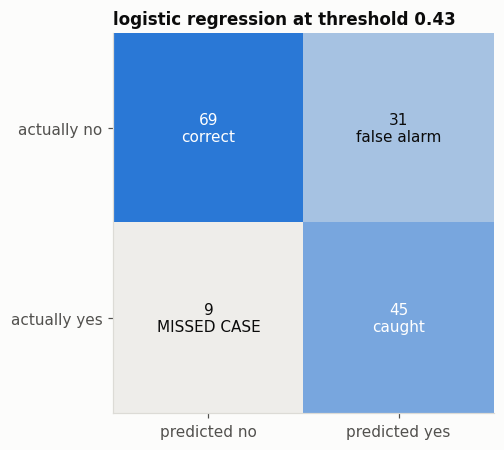

In [10]:
final_name = "logistic_regression"
final_model = best[final_name]
final_proba = final_model.predict_proba(X_test)[:, 1]
final_threshold = evaluate.choose_threshold(y_train, oof[final_name], criterion="f1")

plots.confusion(y_test, final_proba, final_threshold,
                f"{final_name.replace('_', ' ')} at threshold {final_threshold:.2f}");

Nine missed cases out of 54 diabetics. In a screening context those nine are
the number that matters, and the false alarms opposite are the price of keeping
it that low.

Logistic regression is carried forward because it is statistically tied with
the others and is the one that can be interrogated. Notebook 5 takes that up.

---
## Summary

- Four model families score within 0.0055 ROC AUC of each other, against a
  standard deviation of 0.035. The ceiling comes from the data.
- The test set cannot separate them either: a 0.12-wide interval on 154
  patients, with every estimate inside every interval.
- Imputation strategy makes no measurable difference, as notebook 1's
  nested-missingness result suggested.
- Every threshold rule lands between 0.39 and 0.45, well below the 0.5 default.
- Probabilities are not calibrated, because of the balanced class weights.
  Treat them as a ranking.

Next: [4. Clustering](04_clustering.ipynb).